In [14]:
import json
import pandas as pd
import matplotlib.pyplot as plt

In [15]:
# === User configuration ===
file_path = "fedrep_wisdm_results.json"

plt.style.use('seaborn-v0_8')


with open(file_path, "r") as f:
    data = json.load(f)

df = pd.DataFrame(data["round_res"])
print(df.head())

   accuracy      loss
0  0.203125  0.054411
1  0.139992  0.051441
2  0.135980  0.054995
3  0.283361  0.045412
4  0.104307  0.064961


In [22]:
print(df['accuracy'].max())

0.7136824324324325


In [16]:
# === Plotting function (server-wide metric only) ===
def plot_server_metrics(val_pivot, test_metric, test_label, y_label, title):
    plt.figure(figsize=(10, 5))
    plt.plot(val_pivot.index, val_pivot[test_metric], label=test_label, marker='o', color='orange')
    plt.xlabel('Rodada')
    plt.ylabel(y_label)
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()


In [17]:
# === Plotting function ===
def plot_server_metrics(val_pivot, test_metric, test_label, y_label, title):
    plt.figure(figsize=(10, 5))
    plt.plot(val_pivot.index, val_pivot[test_metric], label=test_label, marker='o', color='orange')
    plt.xlabel('Rodada')
    plt.ylabel(y_label)
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()

In [18]:
def update_ema(
    prev_ema,
    current_value: float,
    smoothing_weight: float,
) -> float:
    """We use EMA to visually enhance the learning trend for each round.

    Parameters
    ----------
    prev_ema : float
        The list of metrics to aggregate.
    current_value : float
        The list of metrics to aggregate.
    smoothing_weight : float
        The list of metrics to aggregate.


    Returns
    -------
    EMA_Loss or EMA_ACC
        The weighted average metric.
    """
    if prev_ema is None:
        return current_value
    return (1 - smoothing_weight) * current_value + smoothing_weight * prev_ema
def compute_ema_series(values, smoothing_weight=0.95):
    ema_values = []
    prev_ema = None

    for v in values:
        prev_ema = update_ema(prev_ema, v, smoothing_weight)
        ema_values.append(prev_ema)

    return ema_values
def plot_flower(acc_x, acc_y, loss_x, loss_y, use_ema=False):
    """Visualization of algorithms like 4 Algorithm for data.

    Parameters
    ----------
    directory : str
        Graph params directory path for Femnist or Shakespeare
    """

    if use_ema:
        smoothing_weight = 0.95

        acc_y = compute_ema_series(acc_y, smoothing_weight)
        loss_y = compute_ema_series(loss_y, smoothing_weight)

    color_mapping = {
        "fedmeta_maml": "#FFCC00"
    }

    plt.figure(figsize=(7, 12))


    # Acc graph
    plt.subplot(2, 1, 1)
    plt.plot(
        acc_x,
        acc_y,
        linewidth=3,
        color=color_mapping["fedmeta_maml"],
    )
    plt.title("Accuracy")
    plt.grid(True)
    plt.legend()

    # loss graph
    plt.subplot(2, 1, 2)
    plt.plot(
        loss_x, 
        loss_y, 
        linewidth=3, 
        color=color_mapping["fedmeta_maml"]
    )
    plt.title("Loss")
    plt.legend()
    plt.grid(True)

    plt.tight_layout()

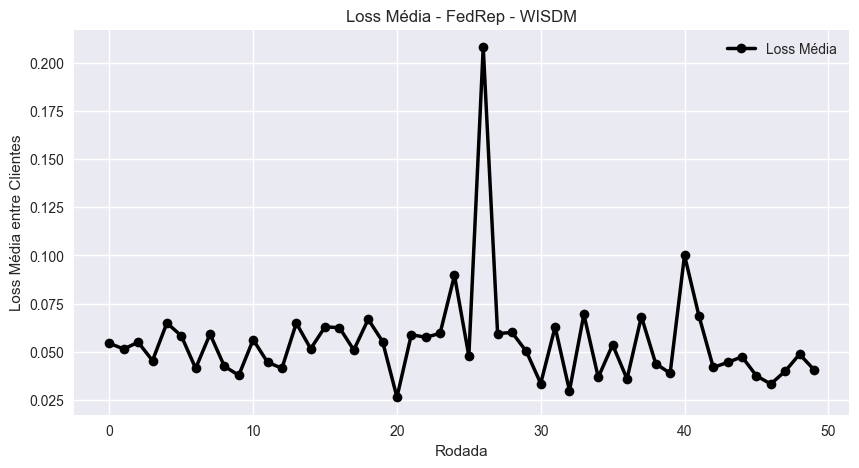

In [19]:
plt.figure(figsize=(10, 5))
plt.plot(df['loss'].index.astype(int), df['loss'].values,
            marker='o', color='black', linewidth=2.5, label='Loss Média')
plt.xlabel('Rodada')
plt.ylabel('Loss Média entre Clientes')
plt.title(f'Loss Média - FedRep - WISDM')
plt.legend()
plt.grid(True)
plt.show()


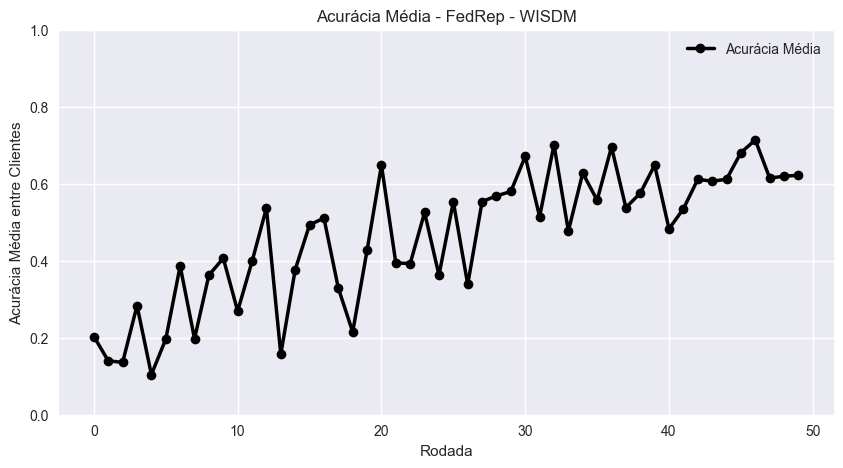

In [20]:
# Plot average
plt.figure(figsize=(10, 5))
plt.plot(df['accuracy'].index.astype(int), df['accuracy'].values,
            marker='o', color='black', linewidth=2.5, label='Acurácia Média')
plt.xlabel('Rodada')
plt.ylabel('Acurácia Média entre Clientes')
plt.ylim(0.0, 1.0)
plt.title(f'Acurácia Média - FedRep - WISDM')
plt.legend()
plt.grid(True)
plt.show()

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


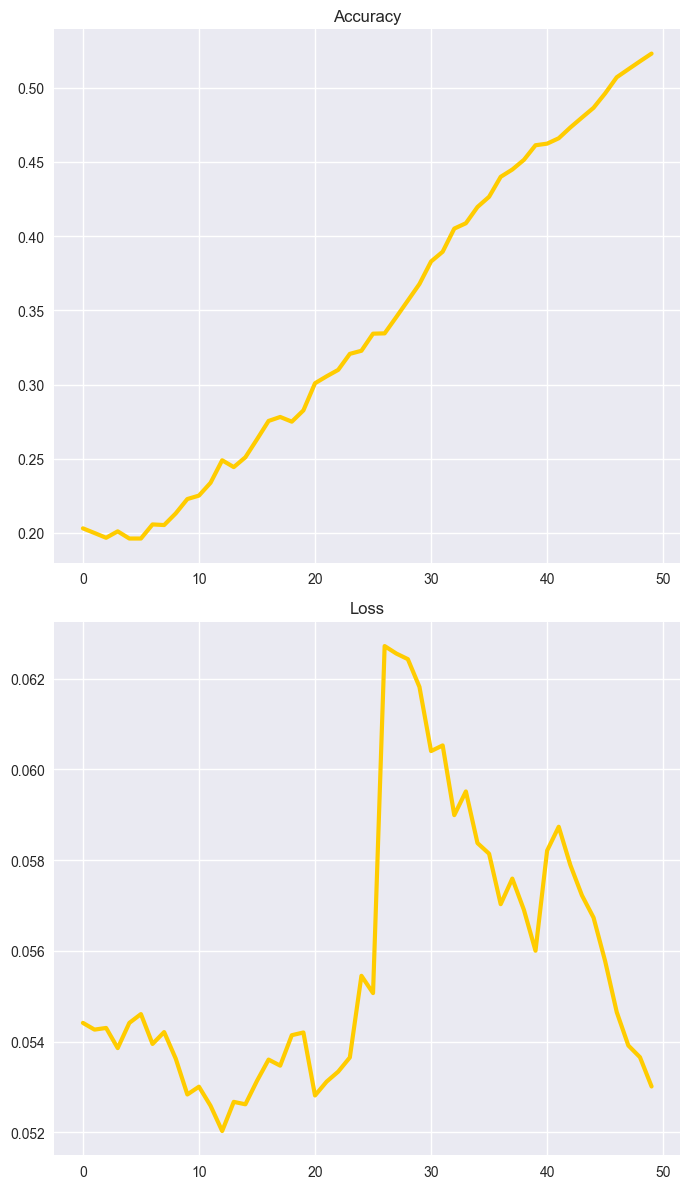

In [21]:
plot_flower(df['accuracy'].index.astype(int), df['accuracy'].values, df['loss'].index.astype(int), df['loss'].values, use_ema=True)